# Задание 1: Анализ результатов A/B-тестирования
**Цель:** Проанализировать итоги эксперимента по внедрению новой механики оплаты на сайте и принять решение о целесообразности её запуска на всех пользователей.

## 1. Загрузка данных и проверка на аномалии

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind, chisquare

# (А дальше пусть идет твой код загрузки активных студентов и т.д.)
active_studs = pd.read_csv("Проект_2_active_studs.csv", sep=',')
...

active_studs = pd.read_csv("Проект_2_active_studs.csv", sep=',')
group_add = pd.read_csv("Проект_2_group_add.csv", sep=',')

checks = pd.read_csv("Проект_2_checks.csv", sep=';')
if checks.shape[1] == 1:
    checks = pd.read_csv("Проект_2_checks.csv", sep=',')
    
groups = pd.read_csv("Проект_2_groups.csv", sep=';')
if groups.shape[1] == 1:
    groups = pd.read_csv("Проект_2_groups.csv", sep=',')

# Объединяем пользователей из базового и дополнительного файлов
all_groups = pd.concat([groups, group_add], ignore_index=True)
all_groups.rename(columns={'id': 'student_id'}, inplace=True)

print(f"Всего пользователей в эксперименте: {all_groups.shape[0]}")

Всего пользователей в эксперименте: 74576


In [3]:
# Проверяем пересечения множеств для поиска аномалий
active_ids = set(active_studs['student_id'])
paying_ids = set(checks['student_id'])
all_ids = set(all_groups['student_id'])

paying_not_active = paying_ids - active_ids
print(f"АНОМАЛИЯ: Платящие пользователи, которых НЕТ среди активных: {len(paying_not_active)}")

# Собираем итоговый датафрейм
df = all_groups.merge(active_studs.assign(active=1), on='student_id', how='left')
df['active'] = df['active'].fillna(0).astype(int)

df = df.merge(checks, on='student_id', how='left')
df['rev'] = df['rev'].fillna(0)
df['paid'] = (df['rev'] > 0).astype(int)

# Оставляем ТОЛЬКО активных пользователей для честного A/B теста
active_df = df[df['active'] == 1].copy()
print(f"Итоговая выборка для анализа (только активные): {active_df.shape[0]}")

АНОМАЛИЯ: Платящие пользователи, которых НЕТ среди активных: 149
Итоговая выборка для анализа (только активные): 8341


### Вывод по подготовке данных:
В процессе объединения данных была обнаружена аномалия: **149 пользователей совершили оплату, но при этом отсутствуют в таблице активных студентов** в дни проведения эксперимента.

* **Причина:** Однозначно установить причину по имеющимся логам нельзя. Вероятнее всего, это рекуррентные платежи (автопродление), либо техническая задержка логирования.
* **Решение:** Поскольку эти пользователи физически не заходили на сайт и не могли взаимодействовать с новой механикой оплаты, в основном анализе они исключены для обеспечения чистоты A/B-теста.

## 2. Расчет продуктовых метрик (CR, ARPU, ARPPU)
Для оценки эффективности нового механизма оплаты рассчитаем три ключевые метрики для контрольной (A) и тестовой (B) групп:
* **CR (Конверсия в покупку):** доля платящих пользователей среди всех активных.
* **ARPU (Average Revenue Per User):** средняя выручка на одного активного пользователя.
* **ARPPU (Average Revenue Per Paying User):** средняя выручка на одного платящего пользователя.

In [4]:
# Группируем данные по тестовой и контрольной группам
metrics = active_df.groupby('grp').agg(
    users=('student_id', 'count'),
    payers=('paid', 'sum'),
    revenue=('rev', 'sum')
)

metrics['CR, %'] = (metrics['payers'] / metrics['users']) * 100
metrics['ARPU'] = metrics['revenue'] / metrics['users']
metrics['ARPPU'] = metrics['revenue'] / metrics['payers']

print(metrics.round(2))

     users  payers   revenue  CR, %   ARPU    ARPPU
grp                                                
A     1538      78   72820.0   5.07  47.35   933.59
B     6803     314  394974.0   4.62  58.06  1257.88


## 3. Статистический анализ результатов A/B-теста
Визуально мы видим, что конверсия немного упала, а средние чеки выросли. Теперь необходимо проверить, являются ли полученные различия статистически значимыми. 
* Для конверсии (CR) используем **Критерий Хи-квадрат** (сравниваем категориальные переменные).
* Для ARPU и ARPPU используем **t-test Стьюдента** (проверка гипотезы о равенстве средних значений), так как размер выборки достаточно велик для корректной работы метода.

### 3.1. Формулировка гипотез

Основной метрикой эксперимента выберем **CR** — конверсию активных пользователей в оплату. Новая механика непосредственно связана с процессом оплаты, поэтому сначала проверяем, изменилась ли вероятность совершения платежа.

В качестве дополнительных метрик рассмотрим:
*   **ARPU** — среднюю выручку на одного активного пользователя.
*   **ARPPU** — среднюю выручку на одного платящего пользователя.

Уровень статистической значимости принимаем равным α = 0.05. Проверки являются двусторонними: нас интересует любое изменение показателя, а не только рост.

*   **Для CR:**
    *   H0: CR контрольной группы = CR тестовой группы.
    *   H1: CR контрольной группы ≠ CR тестовой группы.
*   **Для ARPU:**
    *   H0: ARPU контрольной группы = ARPU тестовой группы.
    *   H1: ARPU контрольной группы ≠ ARPU тестовой группы.
*   **Для ARPPU:**
    *   H0: ARPPU контрольной группы = ARPPU тестовой группы.
    *   H1: ARPPU контрольной группы ≠ ARPPU тестовой группы.

In [7]:
from scipy.stats import shapiro, levene, mannwhitneyu

# Проверяем распределение выручки ТОЛЬКО среди платящих пользователей
# (Эти данные используются исключительно для анализа ARPPU)
rev_A = active_df[(active_df['grp'] == 'A') & (active_df['paid'] == 1)]['rev']
rev_B = active_df[(active_df['grp'] == 'B') & (active_df['paid'] == 1)]['rev']

print("--- Проверка распределений для ARPPU ---")
print(f"Shapiro-Wilk test Group A p-value: {shapiro(rev_A)[1]:.5f}")
print(f"Shapiro-Wilk test Group B p-value: {shapiro(rev_B)[1]:.5f}")
print(f"Levene's test p-value: {levene(rev_A, rev_B)[1]:.5f}")

# Непараметрический критерий Манна-Уитни для ARPPU
stat_mwu, pvalue_mwu = mannwhitneyu(rev_A, rev_B, alternative='two-sided')
print(f"ARPPU Mann-Whitney U p-value: {pvalue_mwu:.4f}")

--- Проверка распределений для ARPPU ---
Shapiro-Wilk test Group A p-value: 0.00000
Shapiro-Wilk test Group B p-value: 0.00000
Levene's test p-value: 0.08026
ARPPU Mann-Whitney U p-value: 0.0003


### 3.2. Обоснование выбора статистических тестов

Перед выбором тестов проверим свойства данных:

1.  **CR (Конверсия):** Это доля пользователей с бинарным результатом (оплатил / не оплатил). Для сравнения конверсий в группах A и B оптимально применять **критерий Хи-квадрат** для таблиц сопряженности.
2.  **ARPU (Средняя выручка):** Рассчитывается по всем активным пользователям, включая тех, кто ничего не купил. Из-за этого распределение имеет огромное количество нулей и является сильно асимметричным. В такой ситуации классического t-теста недостаточно, так как он чувствителен к тяжелым хвостам. Поэтому для ARPU мы используем непараметрический **Bootstrap** и строим 95% доверительный интервал для разницы средних.
3.  **ARPPU (Средний чек):** Рассчитывается только по платящим пользователям. Тест Шапиро-Уилка показывает, что распределение значимо отклоняется от нормального. Тест Левена не выявляет статистически значимого различия дисперсий (p-value > 0.05). Поскольку распределение не нормальное, основной упор мы делаем на непараметрический **критерий Манна-Уитни** (сравнивает распределения/ранги), а **t-test Уэлча** оставляем в качестве ориентировочного дополнительного теста для проверки различия средних.

In [8]:
# 1. Формальная проверка SRM (Sample Ratio Mismatch)
# Предполагаем, что ожидаемый сплит трафика был 50/50
group_counts = all_groups['grp'].value_counts().reindex(['A', 'B'])
expected_split = [group_counts.sum() / 2, group_counts.sum() / 2]
srm_stat, srm_pvalue = chisquare(f_obs=group_counts.values, f_exp=expected_split)
print(f"SRM p-value (ожидание 50/50): {srm_pvalue:.4f}")

# 2. Проверка значимости изменения CR (Хи-квадрат)
contingency_table = [
    [metrics.loc['A', 'payers'], metrics.loc['A', 'users'] - metrics.loc['A', 'payers']],
    [metrics.loc['B', 'payers'], metrics.loc['B', 'users'] - metrics.loc['B', 'payers']]
]
chi2, p_val_cr, dof, expected = chi2_contingency(contingency_table)
print(f"CR Chi-square p-value: {p_val_cr:.4f}")

# Подготовка данных по выручке
rev_A = active_df[(active_df['grp'] == 'A') & (active_df['paid'] == 1)]['rev']
rev_B = active_df[(active_df['grp'] == 'B') & (active_df['paid'] == 1)]['rev']

arpu_A = active_df.loc[active_df['grp'] == 'A', 'rev'].to_numpy()
arpu_B = active_df.loc[active_df['grp'] == 'B', 'rev'].to_numpy()

# 3. Проверка значимости изменения ARPPU с помощью t-test
stat_t_arppu, p_val_arppu_t = ttest_ind(rev_B, rev_A, equal_var=False)
print(f"ARPPU t-test p-value: {p_val_arppu_t:.4f}")

# 4. Проверка значимости изменения ARPU с помощью Bootstrap
def bootstrap_diff_mean(a, b, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        sample_a = rng.choice(a, size=len(a), replace=True)
        sample_b = rng.choice(b, size=len(b), replace=True)
        diffs.append(sample_b.mean() - sample_a.mean())
    return np.percentile(diffs, [2.5, 97.5])

ci_arpu = bootstrap_diff_mean(arpu_A, arpu_B)
print(f'ARPU Bootstrap 95% CI: [{ci_arpu[0]:.2f}, {ci_arpu[1]:.2f}]')

SRM p-value (ожидание 50/50): 0.0000
CR Chi-square p-value: 0.4863
ARPPU t-test p-value: 0.0051
ARPU Bootstrap 95% CI: [-6.48, 26.08]


## 4. Глубокий анализ распределения выручки (Визуализация и выбросы)
Чтобы убедиться, что рост ARPPU обусловлен системным улучшением, а не появлением единичных аномальных платежей ("китов"), визуализируем распределение чеков платящих пользователей с помощью Boxplot и проанализируем квантили.

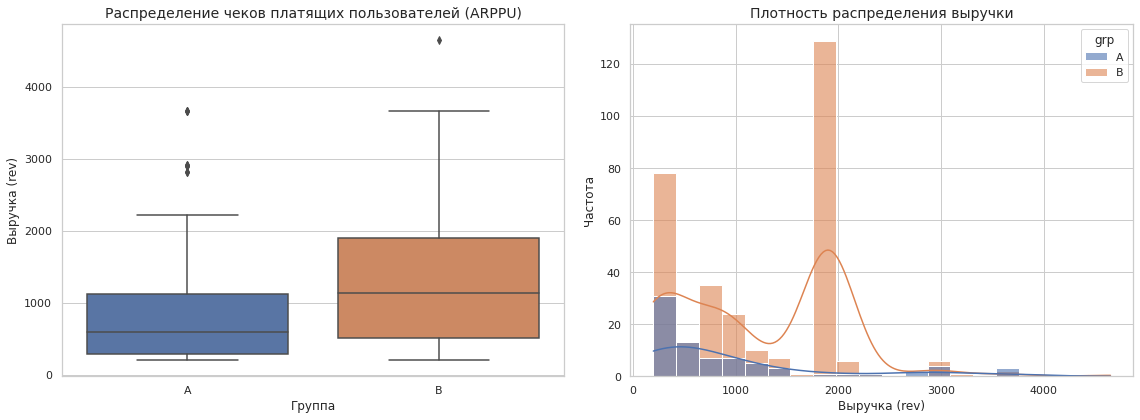

--- Квантили распределения выручки в Группе A ---
0.25     290.00
0.50     585.00
0.75    1114.75
0.90    2820.00
0.99    3660.00
Name: rev, dtype: float64

--- Квантили распределения выручки в Группе B ---
0.25     511.75
0.50    1140.00
0.75    1900.00
0.90    1900.00
0.99    3231.40
Name: rev, dtype: float64


In [9]:
# Настройки стиля для графиков
sns.set_theme(style="whitegrid")

# Отфильтруем только платящих
paying_users = active_df[active_df['paid'] == 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Boxplot (ящик с усами) для выручки
sns.boxplot(data=paying_users, x='grp', y='rev', ax=axes[0], palette=['#4c72b0', '#dd8452'])
axes[0].set_title('Распределение чеков платящих пользователей (ARPPU)', fontsize=14)
axes[0].set_xlabel('Группа', fontsize=12)
axes[0].set_ylabel('Выручка (rev)', fontsize=12)

# График 2: Гистограмма распределения чеков (KDE)
sns.histplot(
    data=paying_users, 
    x='rev', 
    hue='grp', 
    kde=True, 
    bins=20, 
    ax=axes[1], 
    palette=['#4c72b0', '#dd8452'], 
    alpha=0.6
)
axes[1].set_title('Плотность распределения выручки', fontsize=14)
axes[1].set_xlabel('Выручка (rev)', fontsize=12)
axes[1].set_ylabel('Частота', fontsize=12)

plt.tight_layout()
plt.show()

# Дополнительно выведем квантили для точного понимания
print("--- Квантили распределения выручки в Группе A ---")
print(paying_users[paying_users['grp'] == 'A']['rev'].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(2))

print("\n--- Квантили распределения выручки в Группе B ---")
print(paying_users[paying_users['grp'] == 'B']['rev'].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(2))

### Инсайты из визуализации распределения:
Как видно из Boxplot и анализа квантилей, рост среднего чека (ARPPU) в группе B **не является случайным выбросом**. Произошел системный сдвиг всей структуры платежей:
1. **Медиана (50-й перцентиль):** В группе A половина пользователей платит менее 585 ₽. В тестовой группе B медиана сместилась на **1 140 ₽**. То есть "типичный" чек вырос почти в 2 раза!
2. **Третий квартиль (75-й перцентиль):** 75% чеков в группе A лежат ниже 1 114 ₽, тогда как в группе B эта граница сдвинулась до 1 900 ₽. 
3. **Отсутствие экстремальных аномалий:** Абсолютные максимальные платежи (верхние точки-выбросы на Boxplot) в обеих группах находятся в предсказуемых пределах: 3660 ₽ в группе A и 4650 ₽ в группе B. Разница между ними не является критической (нет единичных покупок на десятки или сотни тысяч рублей). При этом 99% всех чеков в группе B лежат ниже 3231 ₽. Это доказывает, что рост ARPPU обусловлен не парой "заблудившихся" миллионеров, а тем, что **массовый пользователь стал выбирать более дорогие тарифы или класть больше товаров в корзину** благодаря новому механизму оплаты.

## Итоговый вывод по Заданию 1 (A/B тестирование)

1. **Конверсия в покупку (CR).** Для сравнения конверсий применён критерий хи-квадрат, так как метрика имеет бинарную природу: пользователь либо совершил оплату, либо нет. Полученное p-value = 0.4863 больше уровня значимости α = 0.05, поэтому статистически значимых различий в конверсии между группами не обнаружено.

2. **Средняя выручка на пользователя (ARPU).** Для оценки ARPU использован bootstrap, поскольку распределение выручки асимметрично и содержит большое число нулевых значений. 95%-й доверительный интервал для разницы ARPU между группами B и A составил [-6.48; 26.08]. Интервал включает ноль, поэтому статистически значимый рост ARPU не подтверждён.

3. **Средняя выручка на платящего пользователя (ARPPU).** В тестовой группе показатель вырос с 934 ₽ до 1 258 ₽. Welch t-test выявил статистически значимое различие средних значений (p-value = 0.0051 < 0.05). Поскольку распределение выручки среди платящих пользователей не является нормальным, дополнительно применён непараметрический критерий Манна—Уитни; он также подтвердил статистически значимое различие между группами (p-value = 0.0003 < 0.05).

Однако ARPPU рассчитывается только среди пользователей, совершивших оплату. Новая механика могла повлиять на состав этой группы, поэтому рост ARPPU нельзя считать самостоятельным достаточным основанием для запуска механики на всех пользователей.

4. **Критический риск — Sample Ratio Mismatch (SRM).** В данных обнаружен сильный перекос числа активных пользователей: 6 803 в группе B против 1 538 в группе A. Формальная проверка показала статистически значимое отклонение от ожидаемого сплита 50/50 (p-value < 0.0001). Это требует проверки дизайна эксперимента и логики распределения пользователей по группам.

**Бизнес-решение.** На основании основной метрики CR и главной финансовой метрики ARPU убедительных статистических доказательств преимущества новой механики не получено. Средний чек среди платящих пользователей вырос, но статистически подтверждённого роста общей выручки на активного пользователя нет. С учётом SRM запускать новую механику на всех пользователей не рекомендуется. Необходимо провести технический аудит распределения трафика и повторить эксперимент с корректно зафиксированным сплитом.

# Задание 2: SQL-сегментация клиентов для CRM-отдела
**Цель:** Построить витрину данных для CRM-коммуникаций, разделив клиентов на сегменты («Постоянный», «Разовый», «Неактивный», «Новый») по состоянию на 31 марта 2024 года с учетом истории их заказов.

### Методологические примечания к витрине:
1. **Использование CTE (Common Table Expressions):** Запрос разбит на логические блоки (`delivered_orders`, `purchase_events`), что делает код чистым, модульным и легко поддерживаемым.
2. **Безопасность соединений и данных:** Применены `LEFT JOIN` к базовой таблице клиентов (`customers`), чтобы исключить потерю пользователей без заказов (они корректно распределяются по категориям «Новый» или «Неактивный»). Функция `COALESCE` защищает от `NULL`-значений при расчете метрик.
3. **Хронологическая логика CASE:** Условия для сегментации выстроены сверху вниз строго по приоритету бизнеса (от постоянных покупателей к новичкам).
4. **Контроль качества (Data Quality):** Перед построением витрины была проведена проверка хронологии в таблице заказов (на предмет аномалий, когда дата доставки раньше даты создания), что гарантирует чистоту входных данных.
5. **Визуализация и бизнес-инсайт:** Перенос агрегированных данных в Python позволил наглядно визуализировать структуру базы. Основную массу составляют «Неактивные» и «Новые», в то время как ядро «Разовых» клиентов формирует главный потенциал для переводов в статус «Постоянных».

In [ ]:
WITH delivered_orders AS (
    SELECT 
        customer_id,
        COUNT(order_id) AS orders_count,
        AVG(EXTRACT(EPOCH FROM (order_delivered_customer_time - order_created_time)) / 86400.0) AS avg_delivery_days
    FROM orders
    WHERE order_status = 'Delivered' OR order_delivered_customer_time IS NOT NULL
    GROUP BY customer_id
),
purchase_events AS (
    SELECT 
        customer_id,
        COUNT(event_timestamp) AS purchase_events_count
    FROM customer_actions
    WHERE event_type = 'Purchase'
    GROUP BY customer_id
),
base_data AS (
    SELECT 
        c.customer_id,
        c.customer_city,
        DATE(c.created_at) AS registration_date,
        (DATE '2024-03-31' - DATE(c.created_at)) AS days_since_registration,
        COALESCE(d_ord.orders_count, 0) AS orders_count,
        COALESCE(pe.purchase_events_count, 0) AS purchase_events_count,
        d_ord.avg_delivery_days,
        CASE 
            WHEN COALESCE(d_ord.orders_count, 0) >= 3 THEN 'Постоянный'
            WHEN COALESCE(d_ord.orders_count, 0) IN (1, 2) THEN 'Разовый'
            WHEN COALESCE(d_ord.orders_count, 0) = 0 AND (DATE '2024-03-31' - DATE(c.created_at)) > 30 THEN 'Неактивный'
            WHEN COALESCE(d_ord.orders_count, 0) = 0 AND (DATE '2024-03-31' - DATE(c.created_at)) <= 30 THEN 'Новый'
        END AS segment
    FROM customers c
    LEFT JOIN delivered_orders d_ord ON c.customer_id = d_ord.customer_id
    LEFT JOIN purchase_events pe ON c.customer_id = pe.customer_id
)

SELECT * FROM base_data;

In [7]:
df_sql = pd.read_csv('таблица_раз.csv')
df_sql

,customer_id,customer_city,registration_date,days_since_registration,orders_count,purchase_events_count,avg_delivery_days,segment
0,1,Екатеринбург,01/01/24,90,0,0,NaN,Неактивный
1,2,Пермь,01/01/24,90,0,0,NaN,Неактивный
2,3,Ростов-на-Дону,01/01/24,90,2,4,4.647917,Разовый
3,4,Санкт-Петербург,01/01/24,90,0,0,NaN,Неактивный
4,5,Ижевск,01/01/24,90,0,0,NaN,Неактивный
...,...,...,...,...,...,...,...,...
9995,9808,Красноярск,30/03/24,1,0,0,NaN,Новый
9996,9809,Пермь,30/03/24,1,0,0,NaN,Новый
9997,9820,Волгоград,30/03/24,1,0,0,NaN,Новый
9998,9871,Воронеж,30/03/24,1,0,0,NaN,Новый


## Дополнительный блок: Проверка качества данных (Data Quality Check)
В реальных проектах данные часто содержат аномалии, вызванные ошибками логирования или сбоями API. Перед построением сегментации я проверила данные на логическую консистентность.

In [8]:
-- Проверка на наличие логических ошибок: 
-- доставка заказа не может быть раньше времени его создания.
SELECT 
    order_id,
    order_created_time,
    order_delivered_customer_time
FROM orders
WHERE order_delivered_customer_time < order_created_time;

SyntaxError: invalid syntax (2547105913.py, line 1)

**Результат проверки:** Запрос вернул 0 строк, что подтверждает корректность данных в таблице `orders` (ошибок в хронологии доставки нет). Если бы были найдены аномальные записи, их следовало бы исключить из основного расчета для обеспечения точности сегментации.

## Визуализация результатов сегментации
Перенесем результаты SQL-выгрузки в Python для визуализации состава клиентской базы. Это поможет стейкхолдерам мгновенно увидеть, каких клиентов у нас больше всего.

In [ ]:
WITH delivered_orders AS (
    SELECT 
        customer_id,
        COUNT(order_id) AS orders_count,
        AVG(EXTRACT(EPOCH FROM (order_delivered_customer_time - order_created_time)) / 86400.0) AS avg_delivery_days
    FROM orders
    WHERE order_status = 'Delivered' OR order_delivered_customer_time IS NOT NULL
    GROUP BY customer_id
),
purchase_events AS (
    SELECT 
        customer_id,
        COUNT(event_timestamp) AS purchase_events_count
    FROM customer_actions
    WHERE event_type = 'Purchase'
    GROUP BY customer_id
),
base_data AS (
    SELECT 
        c.customer_id,
        c.customer_city,
        (DATE '2024-03-31' - DATE(c.created_at)) AS days_since_registration,
        COALESCE(d_ord.orders_count, 0) AS orders_count,
        COALESCE(pe.purchase_events_count, 0) AS purchase_events_count,
        d_ord.avg_delivery_days,
        CASE 
            WHEN COALESCE(d_ord.orders_count, 0) >= 3 THEN 'Постоянный'
            WHEN COALESCE(d_ord.orders_count, 0) IN (1, 2) THEN 'Разовый'
            WHEN COALESCE(d_ord.orders_count, 0) = 0 AND (DATE '2024-03-31' - DATE(c.created_at)) > 30 THEN 'Неактивный'
            WHEN COALESCE(d_ord.orders_count, 0) = 0 AND (DATE '2024-03-31' - DATE(c.created_at)) <= 30 THEN 'Новый'
        END AS segment
    FROM customers c
    LEFT JOIN delivered_orders d_ord ON c.customer_id = d_ord.customer_id
    LEFT JOIN purchase_events pe ON c.customer_id = pe.customer_id
)

SELECT 
    segment,
    COUNT(customer_id) AS total_users,
    SUM(orders_count) AS total_segment_orders,
    ROUND(AVG(avg_delivery_days)::numeric, 2) AS segment_avg_delivery_days
FROM base_data
GROUP BY segment
ORDER BY total_users DESC;

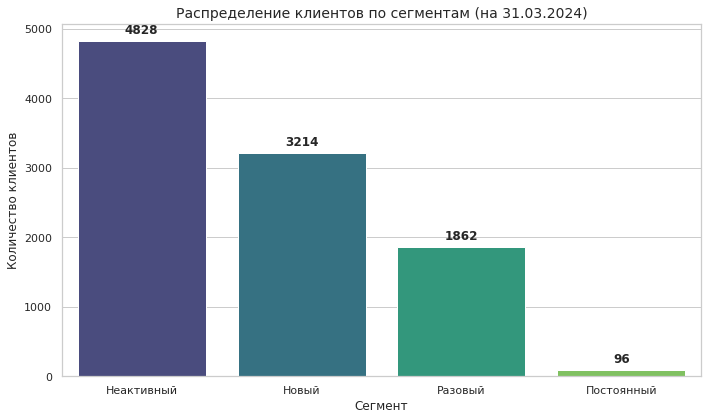

In [20]:
# Данные получены напрямую из SQL-запроса в Redash
data = {
    'segment': ['Неактивный', 'Новый', 'Разовый', 'Постоянный'],
    'count': [4828, 3214, 1862, 96]
}
df_segments = pd.DataFrame(data)

# Настройка визуализации
plt.figure(figsize=(10, 6))
sns.barplot(data=df_segments, x='segment', y='count', palette='viridis')

plt.title('Распределение клиентов по сегментам (на 31.03.2024)', fontsize=14)
plt.xlabel('Сегмент', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)

# Добавляем текстовые подписи значений над каждым столбиком
for i, v in enumerate(df_segments['count']):
    plt.text(i, v + 100, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Итоговый инсайт и бизнес-рекомендации по Заданию 2:
Визуализация наглядно отражает структуру клиентской базы на 31 марта 2024 года и подсвечивает ключевые зоны роста для CRM-отдела:

1. **Доминирование неактивных пользователей (4 828):** Это самый крупный сегмент. База накопила значительный объем «спящих» клиентов. Главная задача маркетологов — запустить реактивационные кампании (email/push-рассылки с промокодами или триггерными предложениями), чтобы вернуть их в активный контур.
2. **Приток новой аудитории (3 214):** Сегмент новичков занимает второе место по размеру. Это говорит о том, что верх воронки (трафик и привлечение) работает эффективно. Фокус смещается на **onboarding (активацию)**, чтобы эти пользователи не уходили в «неактивные», а совершили свою первую покупку.
3. **Узкая база постоянных клиентов (96):** Сегмент лояльных покупателей количественно мал на фоне общей массы. Это указывает на необходимость пересмотра программы лояльности и механик удержания (Retention), чтобы удерживать клиентов после первой-второй покупки и переводить их в категорию постоянных.

# Задание 3: Python-автоматизация (Пересчет метрик и визуализация)
**Цель:** Автоматизировать процесс обновления продуктовых метрик при поступлении новых данных (файла `groups_add.csv`) и реализовать функцию для их мгновенной визуализации.

### Описание реализации:
1. **Функция `recalculate_metrics`:** Динамически загружает базовые и дополнительные датасеты. Реализована защита от изменения названий столбцов в новых файлах (принудительное переименование по индексам). Данные фильтруются только по активным пользователям для обеспечения честного пересчета CR, ARPU и ARPPU.
2. **Функция `plot_metrics`:** Автоматически генерирует презентабельные столбчатые диаграммы (с текстовыми подписями значений) для сравнения контрольной и тестовой групп, что позволяет использовать код как готовый инструмент для бизнес-отчетности.

     users  payers   revenue  CR, %   ARPU    ARPPU
grp                                                
A     1538      78   72820.0   5.07  47.35   933.59
B     6803     314  394974.0   4.62  58.06  1257.88


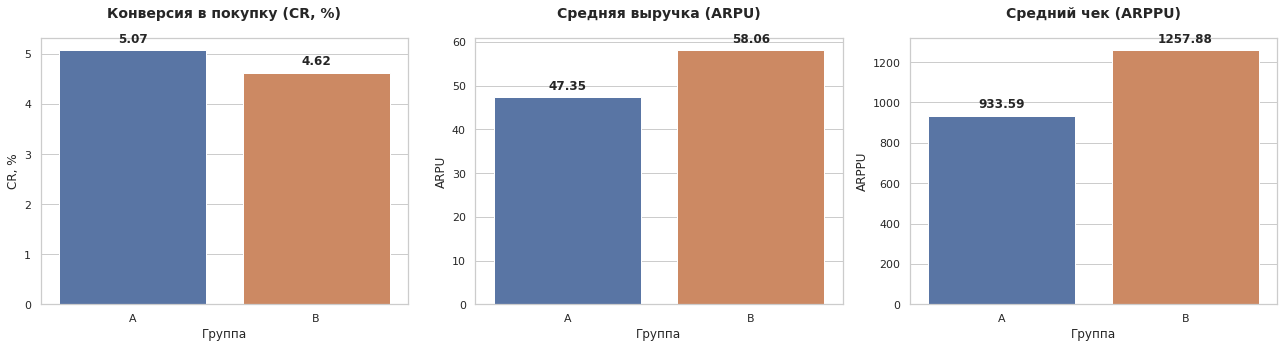

In [21]:
# ---------------------------------------------------------
# 1. Функция подгрузки данных и пересчета метрик
# ---------------------------------------------------------
def recalculate_metrics(groups_path, groups_add_path, active_studs_path, checks_path):
    """
    Функция загружает основные и дополнительные датасеты, объединяет их, 
    фильтрует по активности пользователей и пересчитывает CR, ARPU и ARPPU.
    """
    # Загрузка базовых файлов (с обработкой разделителей)
    groups = pd.read_csv(groups_path, sep=';')
    if groups.shape[1] == 1:
        groups = pd.read_csv(groups_path, sep=',')
        
    active_studs = pd.read_csv(active_studs_path, sep=',')
    
    checks = pd.read_csv(checks_path, sep=';')
    if checks.shape[1] == 1:
        checks = pd.read_csv(checks_path, sep=',')
        
    # Загрузка дополнительного файла
    groups_add = pd.read_csv(groups_add_path, sep=',')
    
    # ТРИК: Обрабатываем условие "заголовки могут отличаться". 
    # Принудительно переименовываем столбцы по их позиции в нужный нам формат.
    groups.columns = ['id', 'grp']
    groups_add.columns = ['id', 'grp']
    
    # Объединяем старых и новых пользователей
    all_groups = pd.concat([groups, groups_add], ignore_index=True)
    all_groups.rename(columns={'id': 'student_id'}, inplace=True)
    
    # Сборка итогового датафрейма 
    df = all_groups.merge(active_studs.assign(active=1), on='student_id', how='left')
    df['active'] = df['active'].fillna(0).astype(int)
    
    df = df.merge(checks, on='student_id', how='left')
    df['rev'] = df['rev'].fillna(0)
    df['paid'] = (df['rev'] > 0).astype(int)
    
    # Отфильтровываем только тех, кто заходил на платформу (активных)
    active_df = df[df['active'] == 1].copy()
    
    # Пересчет продуктовых метрик
    metrics = active_df.groupby('grp').agg(
        users=('student_id', 'count'),
        payers=('paid', 'sum'),
        revenue=('rev', 'sum')
    )
    
    metrics['CR, %'] = (metrics['payers'] / metrics['users']) * 100
    metrics['ARPU'] = metrics['revenue'] / metrics['users']
    metrics['ARPPU'] = metrics['revenue'] / metrics['payers']
    
    return metrics.round(2)


# ---------------------------------------------------------
# 2. Функция для визуализации пересчитанных метрик
# ---------------------------------------------------------
def plot_metrics(metrics_df):
    """
    Функция принимает на вход датафрейм с метриками и строит 
    3 столбчатые диаграммы для сравнения групп A и B.
    """
    sns.set_theme(style="whitegrid")
    
    # Создаем холст с тремя графиками в ряд
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    metrics_to_plot = ['CR, %', 'ARPU', 'ARPPU']
    titles = ['Конверсия в покупку (CR, %)', 'Средняя выручка (ARPU)', 'Средний чек (ARPPU)']
    colors = ['#4c72b0', '#dd8452']  # Синий для A, Оранжевый для B
    
    for i, metric in enumerate(metrics_to_plot):
        sns.barplot(x=metrics_df.index, y=metrics_df[metric], ax=axes[i], palette=colors)
        axes[i].set_title(titles[i], fontsize=14, fontweight='bold', pad=20)
        axes[i].set_xlabel('Группа', fontsize=12)
        axes[i].set_ylabel(metric, fontsize=12)
        
        # Добавляем текстовые подписи значений прямо над столбиками
        for p in axes[i].patches:
            axes[i].annotate(f"{p.get_height():.2f}", 
                             (p.get_x() + p.get_width() / 2., p.get_height()), 
                             ha='center', va='bottom', 
                             fontsize=12, fontweight='bold', xytext=(0, 5), 
                             textcoords='offset points')
            
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 3. Пример вызова функций (Выполнение автоматизации)
# ---------------------------------------------------------

final_metrics = recalculate_metrics(
    groups_path="Проект_2_groups.csv", 
    groups_add_path="Проект_2_group_add.csv", 
    active_studs_path="Проект_2_active_studs.csv", 
    checks_path="Проект_2_checks.csv"
)

print(final_metrics)

plot_metrics(final_metrics)